# S&P 500 Market Movement Predictor

This notebook brings together the work completed so far and leaves us ready to continue with additional market indicators.

**Prediction goal:** Predict whether the S&P 500's return on the next trading day will be positive (`1`) or non-positive (`0`), using information available at the current trading day's close.

## Experiments
1. **Experiment 1:** Baseline technical indicators and Logistic Regression, Random Forest, and SVM.
2. **Experiment 2:** Expanded technical feature engineering.
3. **Experiment 3:** Hyperparameter tuning and comparison.
4. **Experiment 4 (next):** Add VIX and NASDAQ market information.
5. **Experiment 5 (planned):** Add CBOE Put/Call Ratio sentiment data.
6. **Final stage:** Compare the experiments, select a model, and build the prediction application.

Run the notebook from top to bottom. The code cells are included, but outputs will be generated when you run them on your desktop.


## 0. Imports and configuration

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1200)

RANDOM_STATE = 42
N_SPLITS = 5


## 1. Load the S&P 500 dataset

Put the existing `sp500.csv` file in the project's `data/raw/` folder. Since the CSV created on your desktop stores dates as calendar dates, we parse them directly without applying an additional timezone shift.


In [18]:
# Find the CSV whether this notebook is run from the project root or notebooks/ folder
candidate_paths = [
    Path("../data/raw/sp500.csv"),
    Path("data/raw/sp500.csv"),
    Path("sp500.csv")
]
data_path = next((path for path in candidate_paths if path.exists()), None)

if data_path is None:
    raise FileNotFoundError(
        "Could not find sp500.csv. Put it in the project's data/raw/ folder."
    )

df = pd.read_csv(data_path)
df["Date"] = pd.to_datetime(df["Date"]).dt.normalize()
df = df.sort_values("Date").drop_duplicates(subset="Date").reset_index(drop=True)

print("Loaded:", data_path.resolve())
print("Dataset shape:", df.shape)
display(df.head())


Loaded: D:\StockMarketPred_Starter\data\raw\sp500.csv
Dataset shape: (2514, 8)


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2016-11-21,2186.429932,2198.699951,2186.429932,2198.179932,3611500000,0.0,0.0
1,2016-11-22,2201.560059,2204.800049,2194.510010,2202.939941,3960520000,0.0,0.0
2,2016-11-23,2198.550049,2204.719971,2194.510010,2204.719971,3419850000,0.0,0.0
3,2016-11-25,2206.270020,2213.350098,2206.270020,2213.350098,1584590000,0.0,0.0
4,2016-11-28,2210.209961,2211.139893,2200.360107,2201.719971,3515100000,0.0,0.0


In [19]:
print("Dataset information:")
df.info()

print("\nMissing values:")
display(df.isna().sum().to_frame("Missing values"))

print("\nDate range:")
print(df["Date"].min(), "through", df["Date"].max())

print("\nDuplicate dates:", df["Date"].duplicated().sum())


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2514 entries, 0 to 2513
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Date          2514 non-null   datetime64[us]
 1   Open          2514 non-null   float64       
 2   High          2514 non-null   float64       
 3   Low           2514 non-null   float64       
 4   Close         2514 non-null   float64       
 5   Volume        2514 non-null   int64         
 6   Dividends     2514 non-null   float64       
 7   Stock Splits  2514 non-null   float64       
dtypes: datetime64[us](1), float64(6), int64(1)
memory usage: 157.3 KB

Missing values:


,Missing values
Date,0
Open,0
High,0
Low,0
Close,0
Volume,0
Dividends,0
Stock Splits,0



Date range:
2016-11-21 00:00:00 through 2026-11-20 00:00:00

Duplicate dates: 0


## 2. Initial data exploration

Plot the S&P 500 closing price and inspect the distribution of daily percentage returns.


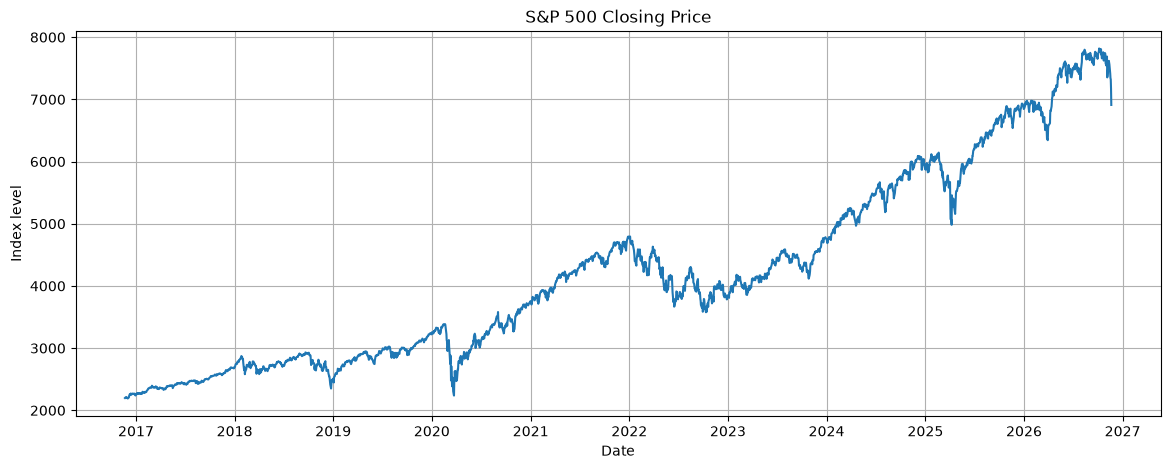

In [20]:
plt.figure(figsize=(14, 5))
plt.plot(df["Date"], df["Close"])
plt.title("S&P 500 Closing Price")
plt.xlabel("Date")
plt.ylabel("Index level")
plt.grid(True)
plt.show()


count    2513.000000
mean        0.000522
std         0.011471
min        -0.119841
25%        -0.003803
50%         0.000769
75%         0.005893
max         0.095154
Name: Daily_Return, dtype: float64

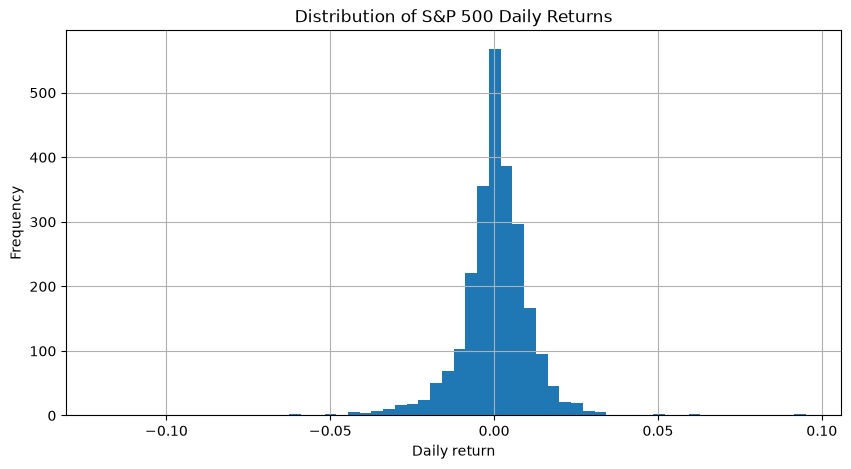

In [21]:
df["Daily_Return"] = df["Close"].pct_change()

display(df["Daily_Return"].describe())

plt.figure(figsize=(10, 5))
plt.hist(df["Daily_Return"].dropna(), bins=60)
plt.title("Distribution of S&P 500 Daily Returns")
plt.xlabel("Daily return")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()


## 3. Create the prediction target and Experiment 1 features

The target uses the **next trading day's** return. A positive return is class `1`; a flat or negative return is class `0`.

All predictors below are calculated from the current day or earlier days, so they are available when making a prediction after the current day's close.


In [22]:
# Moving averages
df["MA5"] = df["Close"].rolling(window=5).mean()
df["MA10"] = df["Close"].rolling(window=10).mean()
df["MA20"] = df["Close"].rolling(window=20).mean()

# Rolling volatility
df["Volatility10"] = df["Daily_Return"].rolling(window=10).std()

# RSI using a 14-day simple rolling average
delta = df["Close"].diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = gain.rolling(window=14).mean()
avg_loss = loss.rolling(window=14).mean()

rs = avg_gain / avg_loss
df["RSI"] = 100 - (100 / (1 + rs))

# Next trading day's return and binary target
df["Next_Day_Return"] = df["Daily_Return"].shift(-1)
df["Target"] = np.where(
    df["Next_Day_Return"].notna(),
    (df["Next_Day_Return"] > 0).astype(int),
    np.nan
)

display(df[[
    "Date", "Close", "Daily_Return", "MA5", "MA10", "MA20",
    "Volatility10", "RSI", "Next_Day_Return", "Target"
]].head(25))


,Date,Close,Daily_Return,MA5,MA10,MA20,Volatility10,RSI,Next_Day_Return,Target
0,2016-11-21,2198.179932,NaN,NaN,NaN,NaN,NaN,NaN,0.002165,1.0
1,2016-11-22,2202.939941,0.002165,NaN,NaN,NaN,NaN,NaN,0.000808,1.0
2,2016-11-23,2204.719971,0.000808,NaN,NaN,NaN,NaN,NaN,0.003914,1.0
3,2016-11-25,2213.350098,0.003914,NaN,NaN,NaN,NaN,NaN,-0.005255,0.0
4,2016-11-28,2201.719971,-0.005255,2204.181982,NaN,NaN,NaN,NaN,0.001335,1.0
5,2016-11-29,2204.659912,0.001335,2205.477979,NaN,NaN,NaN,NaN,-0.002653,0.0
6,2016-11-30,2198.810059,-0.002653,2204.652002,NaN,NaN,NaN,NaN,-0.003516,0.0
7,2016-12-01,2191.080078,-0.003516,2201.924023,NaN,NaN,NaN,NaN,0.000397,1.0
8,2016-12-02,2191.949951,0.000397,2197.643994,NaN,NaN,NaN,NaN,0.005821,1.0
9,2016-12-05,2204.709961,0.005821,2198.241992,2201.211987,NaN,NaN,NaN,0.003411,1.0


In [23]:
features_exp1 = [
    "Daily_Return",
    "MA5",
    "MA10",
    "MA20",
    "Volatility10",
    "RSI"
]

df_exp1 = df.dropna(subset=features_exp1 + ["Target"]).copy()
df_exp1["Target"] = df_exp1["Target"].astype(int)

X_exp1 = df_exp1[features_exp1]
y_exp1 = df_exp1["Target"]

split_exp1 = int(len(df_exp1) * 0.8)

X_train_exp1 = X_exp1.iloc[:split_exp1]
X_test_exp1 = X_exp1.iloc[split_exp1:]
y_train_exp1 = y_exp1.iloc[:split_exp1]
y_test_exp1 = y_exp1.iloc[split_exp1:]

print("Experiment 1 observations:", len(df_exp1))
print("Training rows:", len(X_train_exp1))
print("Testing rows:", len(X_test_exp1))
print("Training dates:", df_exp1["Date"].iloc[0], "to", df_exp1["Date"].iloc[split_exp1 - 1])
print("Testing dates:", df_exp1["Date"].iloc[split_exp1], "to", df_exp1["Date"].iloc[-1])

print("\nTarget distribution:")
display(df_exp1["Target"].value_counts().rename(index={0: "Down/flat", 1: "Up"}))
print("Always-UP baseline on test set:", round((y_test_exp1 == 1).mean(), 4))


Experiment 1 observations: 2494
Training rows: 1995
Testing rows: 499
Training dates: 2016-12-19 00:00:00 to 2024-11-21 00:00:00
Testing dates: 2024-11-22 00:00:00 to 2026-11-19 00:00:00

Target distribution:


Target
Up           1361
Down/flat    1133
Name: count, dtype: int64

Always-UP baseline on test set: 0.5391


## 4. Model definitions and evaluation helpers

We use Logistic Regression, Random Forest, and SVM. Scaling is included in the Logistic Regression and SVM pipelines because these models are sensitive to feature scale. Random Forest does not require feature scaling.


In [24]:
def make_baseline_models():
    return {
        "Logistic Regression": Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
        ]),
        "Random Forest": RandomForestClassifier(
            n_estimators=200,
            max_depth=5,
            min_samples_split=10,
            min_samples_leaf=5,
            random_state=RANDOM_STATE,
            class_weight="balanced"
        ),
        "SVM": Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVC(
                kernel="rbf",
                C=1.0,
                gamma="scale",
                class_weight="balanced"
            ))
        ])
    }


def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0)
    }


def evaluate_on_holdout(models, X_train, y_train, X_test, y_test):
    fitted_models = {}
    rows = []

    for name, model in models.items():
        fitted = clone(model)
        fitted.fit(X_train, y_train)
        predictions = fitted.predict(X_test)

        row = {"Model": name}
        row.update(calculate_metrics(y_test, predictions))
        rows.append(row)
        fitted_models[name] = fitted

    return fitted_models, pd.DataFrame(rows).set_index("Model")


def time_series_cv_evaluate(models, X, y, n_splits=5):
    splitter = TimeSeriesSplit(n_splits=n_splits)
    rows = []

    for name, model in models.items():
        fold_metrics = []

        for train_idx, validation_idx in splitter.split(X):
            fold_model = clone(model)
            fold_model.fit(X.iloc[train_idx], y.iloc[train_idx])
            predictions = fold_model.predict(X.iloc[validation_idx])
            fold_metrics.append(calculate_metrics(y.iloc[validation_idx], predictions))

        fold_df = pd.DataFrame(fold_metrics)
        row = {"Model": name}
        for metric in fold_df.columns:
            row[metric] = fold_df[metric].mean()
        row["Accuracy Std"] = fold_df["Accuracy"].std()
        rows.append(row)

    # Always-UP baseline calculated on the same validation folds
    baseline_accuracy = []
    baseline_balanced_accuracy = []

    for _, validation_idx in splitter.split(X):
        y_validation = y.iloc[validation_idx]
        predictions = np.ones(len(validation_idx), dtype=int)
        baseline_accuracy.append(accuracy_score(y_validation, predictions))
        baseline_balanced_accuracy.append(
            balanced_accuracy_score(y_validation, predictions)
        )

    rows.append({
        "Model": "Always UP baseline",
        "Accuracy": np.mean(baseline_accuracy),
        "Balanced Accuracy": np.mean(baseline_balanced_accuracy),
        "Precision": np.nan,
        "Recall": np.nan,
        "F1": np.nan,
        "Accuracy Std": np.std(baseline_accuracy, ddof=1)
    })

    return pd.DataFrame(rows).set_index("Model")


## 5. Experiment 1 — Baseline model results

In [25]:
baseline_models_exp1 = make_baseline_models()

fitted_exp1, holdout_results_exp1 = evaluate_on_holdout(
    baseline_models_exp1,
    X_train_exp1, y_train_exp1,
    X_test_exp1, y_test_exp1
)

print("Experiment 1 holdout results:")
display(holdout_results_exp1.style.format("{:.4f}"))

print("Always-UP test accuracy:", round((y_test_exp1 == 1).mean(), 4))

for model_name, fitted_model in fitted_exp1.items():
    predictions = fitted_model.predict(X_test_exp1)
    print(f"\n{model_name} confusion matrix:")
    print(confusion_matrix(y_test_exp1, predictions))


Experiment 1 holdout results:


,Accuracy,Balanced Accuracy,Precision,Recall,F1
Model,,,,,
Logistic Regression,0.5291,0.4992,0.5386,0.8810,0.6685
Random Forest,0.5251,0.4901,0.5339,0.9368,0.6802
SVM,0.5411,0.5246,0.5562,0.7361,0.6336


Always-UP test accuracy: 0.5391

Logistic Regression confusion matrix:
[[ 27 203]
 [ 32 237]]

Random Forest confusion matrix:
[[ 10 220]
 [ 17 252]]

SVM confusion matrix:
[[ 72 158]
 [ 71 198]]


### Experiment 1 — Time-series cross-validation

A chronological holdout gives one estimate for a particular period. Time-series cross-validation evaluates multiple sequential validation periods and avoids training on future observations.


In [26]:
cv_results_exp1 = time_series_cv_evaluate(
    baseline_models_exp1,
    X_train_exp1,
    y_train_exp1,
    n_splits=N_SPLITS
)

display(cv_results_exp1.style.format("{:.4f}"))


,Accuracy,Balanced Accuracy,Precision,Recall,F1,Accuracy Std
Model,,,,,,
Logistic Regression,0.4982,0.4956,0.5348,0.6765,0.5693,0.0359
Random Forest,0.4753,0.5027,0.5300,0.3826,0.4003,0.0474
SVM,0.4602,0.4931,0.5151,0.1974,0.2487,0.0487
Always UP baseline,0.5440,0.5000,nan,nan,nan,0.0431


## 6. Experiment 2 — Expanded feature engineering

We add moving-average ratios, 5-day and 10-day momentum, and 20-day volatility. This expands the feature set from 6 to 9 features.


In [27]:
df["MA5_Ratio"] = (df["Close"] / df["MA5"]) - 1
df["MA10_Ratio"] = (df["Close"] / df["MA10"]) - 1
df["MA20_Ratio"] = (df["Close"] / df["MA20"]) - 1

df["Momentum5"] = df["Close"].pct_change(5)
df["Momentum10"] = df["Close"].pct_change(10)
df["Volatility20"] = df["Daily_Return"].rolling(window=20).std()

features_exp2 = [
    "Daily_Return",
    "MA5_Ratio",
    "MA10_Ratio",
    "MA20_Ratio",
    "Momentum5",
    "Momentum10",
    "Volatility10",
    "Volatility20",
    "RSI"
]

df_exp2 = df.dropna(subset=features_exp2 + ["Target"]).copy()
df_exp2["Target"] = df_exp2["Target"].astype(int)

X_exp2 = df_exp2[features_exp2]
y_exp2 = df_exp2["Target"]

split_exp2 = int(len(df_exp2) * 0.8)

X_train_exp2 = X_exp2.iloc[:split_exp2]
X_test_exp2 = X_exp2.iloc[split_exp2:]
y_train_exp2 = y_exp2.iloc[:split_exp2]
y_test_exp2 = y_exp2.iloc[split_exp2:]

print("Experiment 2 observations:", len(df_exp2))
print("Training rows:", len(X_train_exp2))
print("Testing rows:", len(X_test_exp2))
print("Always-UP baseline on test set:", round((y_test_exp2 == 1).mean(), 4))
display(df_exp2[["Date"] + features_exp2 + ["Target"]].head())


Experiment 2 observations: 2493
Training rows: 1994
Testing rows: 499
Always-UP baseline on test set: 0.5391


,Date,Daily_Return,MA5_Ratio,MA10_Ratio,MA20_Ratio,Momentum5,Momentum10,Volatility10,Volatility20,RSI,Target
20,2016-12-20,0.003638,0.004168,0.005543,0.018082,-0.000423,0.026457,0.005670,0.004702,76.192220,0
21,2016-12-21,-0.002457,0.000648,0.002015,0.014165,0.005281,0.010632,0.004470,0.004787,77.403802,0
22,2016-12-22,-0.001863,-0.001122,-0.000505,0.011003,-0.000473,0.006576,0.004541,0.004842,74.904361,1
23,2016-12-23,0.001252,-0.000377,0.000558,0.011128,0.002533,0.001885,0.004162,0.004802,72.966889,1
24,2016-12-27,0.002248,0.001309,0.002279,0.011884,0.002807,0.005281,0.004179,0.004563,72.446283,0


In [28]:
cv_results_exp2 = time_series_cv_evaluate(
    make_baseline_models(),
    X_train_exp2,
    y_train_exp2,
    n_splits=N_SPLITS
)

print("Experiment 2 cross-validation results:")
display(cv_results_exp2.style.format("{:.4f}"))


Experiment 2 cross-validation results:


,Accuracy,Balanced Accuracy,Precision,Recall,F1,Accuracy Std
Model,,,,,,
Logistic Regression,0.5277,0.4918,0.5366,0.8800,0.6616,0.0549
Random Forest,0.5072,0.5012,0.5384,0.5873,0.5521,0.0412
SVM,0.4886,0.4807,0.5219,0.5996,0.5457,0.0419
Always UP baseline,0.5440,0.5000,nan,nan,nan,0.0431


## 7. Experiment 3 — Hyperparameter tuning

GridSearchCV searches for model configurations using chronological `TimeSeriesSplit` folds. The parameter grids below match the tuning experiments we previously worked through.


In [29]:
tscv = TimeSeriesSplit(n_splits=N_SPLITS)

# Logistic Regression
logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

logistic_grid = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

logistic_search = GridSearchCV(
    logistic_pipeline,
    logistic_grid,
    scoring="accuracy",
    cv=tscv,
    n_jobs=-1
)

# Random Forest
rf_model = RandomForestClassifier(
    class_weight="balanced",
    random_state=RANDOM_STATE
)

rf_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 10, None],
    "min_samples_split": [5, 10, 20],
    "min_samples_leaf": [2, 5, 10]
}

rf_search = GridSearchCV(
    rf_model,
    rf_grid,
    scoring="accuracy",
    cv=tscv,
    n_jobs=-1
)

# Support Vector Machine
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="rbf", class_weight="balanced"))
])

svm_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.001, 0.01, 0.1, 1]
}

svm_search = GridSearchCV(
    svm_pipeline,
    svm_grid,
    scoring="accuracy",
    cv=tscv,
    n_jobs=-1
)

searches = {
    "Logistic Regression": logistic_search,
    "Random Forest": rf_search,
    "SVM": svm_search
}

for name, search in searches.items():
    print(f"\nTuning {name}...")
    search.fit(X_train_exp2, y_train_exp2)
    print("Best CV accuracy:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)



Tuning Logistic Regression...
Best CV accuracy: 0.5434
Best parameters: {'model__C': 0.001}

Tuning Random Forest...
Best CV accuracy: 0.5253
Best parameters: {'max_depth': 3, 'min_samples_leaf': 10, 'min_samples_split': 5, 'n_estimators': 100}

Tuning SVM...
Best CV accuracy: 0.544
Best parameters: {'model__C': 0.1, 'model__gamma': 0.001}


### Experiment 3 — Tuned-model cross-validation predictions

`cross_val_predict` does not directly work with `TimeSeriesSplit` because the earliest observations are never validation observations. We therefore create out-of-fold predictions manually, using only the validation portion of each chronological fold.


In [30]:
def time_series_oof_predictions(estimator, X, y, n_splits=5):
    splitter = TimeSeriesSplit(n_splits=n_splits)
    actual_all = []
    predicted_all = []

    for train_idx, validation_idx in splitter.split(X):
        fold_model = clone(estimator)
        fold_model.fit(X.iloc[train_idx], y.iloc[train_idx])

        predictions = fold_model.predict(X.iloc[validation_idx])

        actual_all.extend(y.iloc[validation_idx].tolist())
        predicted_all.extend(predictions.tolist())

    return np.asarray(actual_all), np.asarray(predicted_all)


oof_rows = []

for name, search in searches.items():
    oof_actual, oof_predicted = time_series_oof_predictions(
        search.best_estimator_,
        X_train_exp2,
        y_train_exp2,
        n_splits=N_SPLITS
    )

    row = {"Model": name}
    row.update(calculate_metrics(oof_actual, oof_predicted))
    oof_rows.append(row)

    print(f"\n{name} OOF confusion matrix:")
    print(confusion_matrix(oof_actual, oof_predicted))

tuned_oof_results = pd.DataFrame(oof_rows).set_index("Model")
display(tuned_oof_results.style.format("{:.4f}"))



Logistic Regression OOF confusion matrix:
[[  0 757]
 [  1 902]]

Random Forest OOF confusion matrix:
[[267 490]
 [298 605]]

SVM OOF confusion matrix:
[[  0 757]
 [  0 903]]


,Accuracy,Balanced Accuracy,Precision,Recall,F1
Model,,,,,
Logistic Regression,0.5434,0.4994,0.5437,0.9989,0.7041
Random Forest,0.5253,0.5113,0.5525,0.6700,0.6056
SVM,0.5440,0.5000,0.5440,1.0000,0.7046


### Experiment 3 — Final chronological holdout evaluation

After tuning on the training portion, evaluate each best estimator on the later holdout period. The holdout period was examined during our earlier work, so it should not be described as a completely untouched final test set in the project report.


In [31]:
tuned_holdout_rows = []
tuned_fitted_models = {}

for name, search in searches.items():
    best_model = clone(search.best_estimator_)
    best_model.fit(X_train_exp2, y_train_exp2)

    predictions = best_model.predict(X_test_exp2)

    row = {"Model": name}
    row.update(calculate_metrics(y_test_exp2, predictions))
    tuned_holdout_rows.append(row)
    tuned_fitted_models[name] = best_model

    print(f"\n{name} holdout confusion matrix:")
    print(confusion_matrix(y_test_exp2, predictions))

tuned_holdout_results = pd.DataFrame(tuned_holdout_rows).set_index("Model")

print("Tuned models — holdout results:")
display(tuned_holdout_results.style.format("{:.4f}"))

print("Always-UP test accuracy:", round((y_test_exp2 == 1).mean(), 4))



Logistic Regression holdout confusion matrix:
[[  1 229]
 [  0 269]]

Random Forest holdout confusion matrix:
[[ 60 170]
 [ 64 205]]

SVM holdout confusion matrix:
[[230   0]
 [269   0]]
Tuned models — holdout results:


,Accuracy,Balanced Accuracy,Precision,Recall,F1
Model,,,,,
Logistic Regression,0.5411,0.5022,0.5402,1.0000,0.7014
Random Forest,0.5311,0.5115,0.5467,0.7621,0.6366
SVM,0.4609,0.5000,0.0000,0.0000,0.0000


Always-UP test accuracy: 0.5391


## 8. Compare the experiments

This table summarizes the mean time-series cross-validation accuracy from the three feature/model stages. Run the cells above first so the result variables exist.


In [32]:
experiment_comparison = pd.DataFrame({
    "Experiment 1 — Original features": cv_results_exp1.loc[
        ["Logistic Regression", "Random Forest", "SVM"], "Accuracy"
    ],
    "Experiment 2 — Engineered features": cv_results_exp2.loc[
        ["Logistic Regression", "Random Forest", "SVM"], "Accuracy"
    ],
    "Experiment 3 — Tuned features": pd.Series({
        name: search.best_score_ for name, search in searches.items()
    })
})

display(experiment_comparison.style.format("{:.4f}"))


,Experiment 1 — Original features,Experiment 2 — Engineered features,Experiment 3 — Tuned features
Logistic Regression,0.4982,0.5277,0.5434
Random Forest,0.4753,0.5072,0.5253
SVM,0.4602,0.4886,0.5440
